# 08 · TypeSafe Jev

This notebook evaluates two tagging methods that ask TypeSafe's Jev model (`jev-1.13.0`) one
yes/no question per focus tag, each with the tag's definition, and turn the probability Jev
answers into a tag through cross-fitted thresholds. `jev-statement` shows Jev the statement;
`jev-statement-code` shows it the statement and the solution. Both are compared with the label
prior (the F1 floor), the TF-IDF baseline and the two fine-tuned ModernBERT models, on the dev
set out of fold and, at the very end, on the test set.

**Contents**
1. Setup and checks
2. What Jev is asked
3. The dev set, out of fold
4. The statement against the statement and the solution
5. Calibration
6. Slices: release era and self-identifying solutions
7. Agreement and errors
8. The test set, reported once
9. Latency
10. Takeaways and next steps

**How it was built**
- **Fixed before any answer.** The question, the convention and the eight tag definitions
  were written from Codeforces conventions, without reading a dev problem or an answer, and
  every request's hash covers them
  ([ADR 0007](../docs/adr/0007-api-score-methods-share-the-llm-toolkit.md)). Neither method
  is `dev_in_sample`, and both were fixed before the first test request.
- **The answers files are the record.** Each answer is a line of the method's committed,
  append-only `answers_dev.jsonl` or `answers_test.jsonl`, and `freeze` derived every frozen
  file from them offline
  ([ADR 0003](../docs/adr/0003-api-methods-are-fixed-reference-models.md)). This notebook
  sends no request and needs no key.
- **Cross-fitted thresholds.** Jev's probabilities are the scores, and the scorer learns
  nothing, so each dev problem is predicted with per-tag thresholds chosen on the other four
  folds, as for TF-IDF and ModernBERT
  ([ADR 0001](../docs/adr/0001-model-selection-protocol.md)). An answer that failed scores 0
  on every tag.
- **Dev first.** Every comparison and the error analysis read the dev set, out of fold. The
  test set is reported once, in section 8, and nothing is chosen from it.
- **Macro F1 is the primary metric**: the unweighted mean of the 8 per-tag F1 scores. Micro
  F1 pools the counts of the 8 tags, so the frequent tags weigh more in it.
- **Intervals come from a group bootstrap**: 2,000 resamples of near-duplicate groups, 95%
  percentile intervals. Every method is scored on the same resamples, so a paired difference
  between two methods has its own interval.

**Running it.** It reads the frozen files of `label_prior`, `jev-statement`,
`jev-statement-code`, `tfidf`, `modernbert_lora` and `modernbert_base_full` (`assets/methods/`),
and the dataset, from an absolute `CODEFORCES_DATA_DIR` (the kernel runs in `notebooks/`). It
needs no API key, no TypeSafe SDK and no GPU, and runs in about a minute.

## 1. Setup and checks

Every import and setting first, then the dev and test sets, then each method's frozen files,
checked before they are used.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from codeforces_tags.analysis.calibration import expected_calibration_error, reliability_table
from codeforces_tags.analysis.comparison import agreement, method_scores
from codeforces_tags.analysis.error_analysis import misclassified
from codeforces_tags.analysis.plotting import (
    plot_intervals,
    plot_latency,
    plot_method_f1,
    plot_reliability_table,
    setup_style,
)
from codeforces_tags.config import FOCUS_TAGS, LATENCY_BUDGET_S
from codeforces_tags.conformance import check_frozen_method
from codeforces_tags.data.labels import focus_labels
from codeforces_tags.data.loading import load_dataset, read_samples
from codeforces_tags.evaluation.contamination import load_slice
from codeforces_tags.evaluation.predictions import (
    load_per_problem,
    load_predictions,
    load_run_record,
    load_scores,
)
from codeforces_tags.evaluation.report import ALL_PROBLEMS, compare, evaluate
from codeforces_tags.evaluation.timing import latency_summary, load_latency
from codeforces_tags.llm.store import answers_file, read_answers
from codeforces_tags.methods import load_method, method_dir, model_dir
from codeforces_tags.methods.typesafe_jev import questions
from codeforces_tags.methods.typesafe_jev.settings import FROZEN_NAMES as NAMES
from codeforces_tags.methods.typesafe_jev.settings import MODEL
from codeforces_tags.model.thresholds import apply_thresholds
from codeforces_tags.splitting import PARTS, load_split, release_years, select_part

setup_style()
pd.set_option("display.max_colwidth", 110)
# A reliability table has 30 columns (3 per bin): Jupyter's default of 20 would hide some.
pd.set_option("display.max_columns", 40)
TAGS = list(FOCUS_TAGS)
METRICS = ["macro_f1", "micro_f1", *TAGS]
PRIOR, TFIDF = "label_prior", "tfidf"
LORA, BASE_FULL = "modernbert-lora", "modernbert-base-full"

In [2]:
problems = load_dataset()
split = load_split()
dev, test = select_part(problems, split, "dev"), select_part(problems, split, "test")
dev_labels, test_labels = focus_labels(dev), focus_labels(test)
folds, groups, years = dev["fold"], dev["group"], release_years(dev)
print(
    f"dev set: {len(dev):,} problems, {groups.nunique():,} near-duplicate groups, "
    f"{folds.nunique()} folds; test set: {len(test):,} problems"
)

dev set: 3,988 problems, 3,919 near-duplicate groups, 5 folds; test set: 994 problems


In [3]:
records, jev_scores, dev_by_method, test_by_method = {}, {}, {}, {}
for name in [PRIOR, *NAMES]:
    check_frozen_method(name, split=split)
    records[name] = load_run_record(method_dir(name))
    assert records[name].method == name
    assert records[name].method_entries["dev_in_sample"] is False, name
    frozen = load_predictions(method_dir(name))
    dev_by_method[name] = frozen.loc["dev", TAGS]
    test_by_method[name] = frozen.loc["test", TAGS]
    assert dev_by_method[name].index.equals(dev.index), name
    assert test_by_method[name].index.equals(test.index), name
for name in NAMES:
    jev_scores[name] = load_scores(method_dir(name)).loc[:, TAGS]
    assert records[name].method_entries["served_models"] == [MODEL], name
# The label prior predicts every tag for every problem: its F1 on a tag is 2p / (1 + p).
share = dev_labels.mean()
assert np.allclose(evaluate(dev_labels, dev_by_method[PRIOR]).tag_f1, 2 * share / (1 + share))
print(f"frozen and checked: {list(dev_by_method)}")

frozen and checked: ['label_prior', 'jev-statement', 'jev-statement-code']


In [4]:
check_frozen_method(TFIDF, split=split)
frozen = load_predictions(method_dir(TFIDF))
dev_by_method[TFIDF] = frozen.loc["dev", TAGS]
test_by_method[TFIDF] = frozen.loc["test", TAGS]
assert dev_by_method[TFIDF].index.equals(dev.index)
assert test_by_method[TFIDF].index.equals(test.index)
tfidf_macro = evaluate(dev_labels, dev_by_method[TFIDF]).macro_f1
print(f"TF-IDF, the frozen method {TFIDF}, out of fold: macro F1 {tfidf_macro:.4f}")

TF-IDF, the frozen method tfidf, out of fold: macro F1 0.6629


In [5]:
MODERNBERT_METHODS = {LORA: "modernbert_lora", BASE_FULL: "modernbert_base_full"}
modernbert_latency = {}
for name, registered in MODERNBERT_METHODS.items():
    check_frozen_method(registered, split=split)
    frozen = load_predictions(method_dir(registered))
    dev_by_method[name] = frozen.loc["dev", TAGS]
    test_by_method[name] = frozen.loc["test", TAGS]
    modernbert_latency[f"{name}, bag of five"] = load_latency(method_dir(registered)).seconds
print(f"ModernBERT's frozen methods: {list(MODERNBERT_METHODS.values())}")

ModernBERT's frozen methods: ['modernbert_lora', 'modernbert_base_full']


ModernBERT's dev predictions come from each of its five fold models, out of fold, through
cross-fitted thresholds over the five dev folds; its test predictions come from the bag of the
five, through the thresholds chosen on every dev problem, as its frozen methods saved them.
TF-IDF is the frozen method `tfidf`: its dev predictions are out of fold, through cross-fitted
thresholds, and its test predictions use the thresholds chosen on every dev problem, so it gets
intervals and paired differences like the other methods.

ModernBERT's configuration was chosen on dev fold 0 (ADR 0005), so its out-of-fold score carries
a little of that choice, and TF-IDF's is the score of the best configuration of its tuning
study; the Jev methods chose nothing on dev. Section 3 therefore also compares them with
ModernBERT on folds 1-4 alone.

## 2. What Jev is asked

Each method sends one request per problem, Jev's `system_one` call: the problem's state (the
statement, and for `jev-statement-code` the solution too) and eight Noul questions, one per
focus tag. Each question asks whether Codeforces would put the tag on the problem, with a
convention (a tag names an idea of the intended solution) and the tag's definition: what counts
as a yes, with what it includes, and what counts as a no, with what it excludes. Jev answers
each question with a probability. The sha256 of the exact bytes sent keys the answer in the
answers file. Below, the request of the first dev problem whose `jev-statement-code` answer
completed: its state in full, then its question about `number theory`.

In [6]:
raw_dev = select_part(read_samples(), split, "dev")
code_answers = {
    answer.sample_id: answer for answer in read_answers(answers_file("jev-statement-code", "dev"))
}
first = next(
    sample_id for sample_id in raw_dev.index if code_answers[sample_id].status == "completed"
)
request = questions.requests(raw_dev.loc[[first]], "jev-statement-code")[0]
answer = code_answers[first]
assert answer.request_sha256 == request.sha256()  # the answer is filed under its request
print(f"problem {request.sample_id}, model {request.model}, request {request.sha256()[:12]}")
for field, text in request.state.items():
    print(f"\n{field}, {len(text):,} characters:\n{text}")
print(f"\nquestions: {list(request.questions)}\n")
print(json.dumps(request.questions[questions.question_id("number theory")], indent=2))

problem 0, model jev-1.13.0, request 522634dd86f5

statement, 1,498 characters:
Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one operation you can erase any two numbers $$$a$$$ and $$$b$$$ from the board and write one integer $$$\frac{a + b}{2}$$$ rounded up instead. You should perform the given operation $$$n - 1$$$ times and make the resulting number that will be left on the board as small as possible. For example, if $$$n = 4$$$, the following course of action is optimal:  choose $$$a = 4$$$ and $$$b = 2$$$, so the new number is $$$3$$$, and the whiteboard contains $$$[1, 3, 3]$$$;  choose $$$a = 3$$$ and $$$b = 3$$$, so the new number is $$$3$$$, and the whiteboard contains $$$[1, 3]$$$;  choose $$$a = 1$$$ and $$$b = 3$$$, so the new number is $$$2$$$, and the whiteboard contains $$$[2]$$$. It's easy to see that after $$$n - 1$$$ operations, there will be left only one number. Your goal is to minimize it.

The first line con

In [7]:
print(
    f"answer: {answer.status}, served by {answer.served_model}, "
    f"{answer.usage['input_tokens']:,} input tokens, {answer.latency_s:.2f} s"
)
pd.Series(json.loads(answer.output_text), name="probability").round(3)

answer: completed, served by jev-1.13.0, 2,993 input tokens, 0.29 s


math             0.27
graphs           0.03
strings          0.02
number theory    0.07
trees            0.07
geometry         0.02
games            0.04
probabilities    0.02
Name: probability, dtype: float64

Every answer of both methods: how many failed, the tokens they used, how long each took, and
what they cost at Jev's price (`config.LLM_PRICES`), from each method's `per_problem.csv`; then
each answer's status, and the models that answered, from the run records.

In [8]:
calls = pd.concat({name: load_per_problem(method_dir(name)) for name in NAMES}, names=["method"])
by_part = calls.groupby(level=["method", "part"], sort=False)
failed = (calls["status"] != "completed").groupby(level=["method", "part"], sort=False).sum()
usage = pd.DataFrame(
    {
        "problems": by_part.size(),
        "failed": failed,
        "input_tokens": by_part["input_tokens"].sum(),
        "input_tokens_per_problem": by_part["input_tokens"].mean().round(),
        "output_tokens": by_part["output_tokens"].sum(),
        "median_latency_s": by_part["latency_s"].median(),
        "cost_usd": by_part["total_cost_usd"].sum(),
    }
)
for name in NAMES:
    for part in PARTS:
        recorded = records[name].method_entries["answers"][part]["cost_usd"]
        assert np.isclose(usage.at[(name, part), "cost_usd"], recorded, rtol=1e-9, atol=0)
served = {name: records[name].method_entries["served_models"] for name in NAMES}
display(by_part["status"].value_counts().unstack(fill_value=0))
print(f"models that answered: {served}; all answers cost ${usage['cost_usd'].sum():.4f}")
usage.round(4)

status                   completed
method             part           
jev-statement      dev        3988
                   test        994
jev-statement-code dev        3988
                   test        994

models that answered: {'jev-statement': ['jev-1.13.0'], 'jev-statement-code': ['jev-1.13.0']}; all answers cost $1.2472


problems  failed  input_tokens  \
method             part                                   
jev-statement      dev       3988       0      11047899   
                   test       994       0       2754375   
jev-statement-code dev       3988       0      12752655   
                   test       994       0       3139371   

                         input_tokens_per_problem  output_tokens  \
method             part                                            
jev-statement      dev                     2770.0         542368   
                   test                    2771.0         135184   
jev-statement-code dev                     3198.0         542368   
                   test                    3158.0         135184   

                         median_latency_s  cost_usd  
method             part                              
jev-statement      dev             0.2262    0.4640  
                   test            0.2270    0.1157  
jev-statement-code dev             0.2263    0.5356  
                   test            0.2277    0.1319

## 3. The dev set, out of fold

Every method is scored on the 3,988 dev problems, on the same group bootstrap resamples: the two
Jev methods, TF-IDF and ModernBERT through cross-fitted thresholds over the five dev folds, and
the label prior as it is (it predicts every tag for every problem). First each method's F1, then
the intervals and the paired differences with the label prior of the macro and micro F1.

In [9]:
dev_scores = method_scores(dev_labels, dev_by_method, groups, baseline=PRIOR)
dev_f1 = dev_scores["f1"].unstack("method").reindex(index=METRICS, columns=list(dev_by_method))
dev_f1.round(3)

method,label_prior,jev-statement,jev-statement-code,tfidf,modernbert-lora,modernbert-base-full
metric,,,,,,
macro_f1,0.149,0.729,0.729,0.663,0.661,0.653
micro_f1,0.158,0.675,0.684,0.617,0.628,0.611
math,0.441,0.630,0.638,0.582,0.611,0.578
graphs,0.196,0.670,0.704,0.603,0.602,0.623
strings,0.156,0.686,0.660,0.690,0.665,0.636
number theory,0.130,0.682,0.687,0.541,0.585,0.596
trees,0.123,0.782,0.801,0.719,0.650,0.654
geometry,0.065,0.748,0.761,0.652,0.683,0.658
games,0.041,0.875,0.830,0.835,0.750,0.756


In [10]:
dev_scores[dev_scores.index.get_level_values("metric").isin(["macro_f1", "micro_f1"])].round(3)

f1  f1_low  f1_high  delta  delta_low  \
method               metric                                               
label_prior          macro_f1  0.149   0.144    0.153  0.000      0.000   
                     micro_f1  0.158   0.153    0.163  0.000      0.000   
jev-statement        macro_f1  0.729   0.710    0.747  0.580      0.562   
                     micro_f1  0.675   0.662    0.689  0.518      0.505   
jev-statement-code   macro_f1  0.729   0.710    0.746  0.581      0.561   
                     micro_f1  0.684   0.670    0.698  0.526      0.513   
tfidf                macro_f1  0.663   0.642    0.683  0.514      0.494   
                     micro_f1  0.617   0.604    0.632  0.460      0.447   
modernbert-lora      macro_f1  0.661   0.642    0.680  0.513      0.493   
                     micro_f1  0.628   0.614    0.643  0.470      0.457   
modernbert-base-full macro_f1  0.653   0.632    0.671  0.504      0.483   
                     micro_f1  0.611   0.596    0.625  0.453      0.440   

                               delta_high  
method               metric                
label_prior          macro_f1       0.000  
                     micro_f1       0.000  
jev-statement        macro_f1       0.597  
                     micro_f1       0.530  
jev-statement-code   macro_f1       0.598  
                     micro_f1       0.539  
tfidf                macro_f1       0.534  
                     micro_f1       0.473  
modernbert-lora      macro_f1       0.531  
                     micro_f1       0.484  
modernbert-base-full macro_f1       0.522  
                     micro_f1       0.466

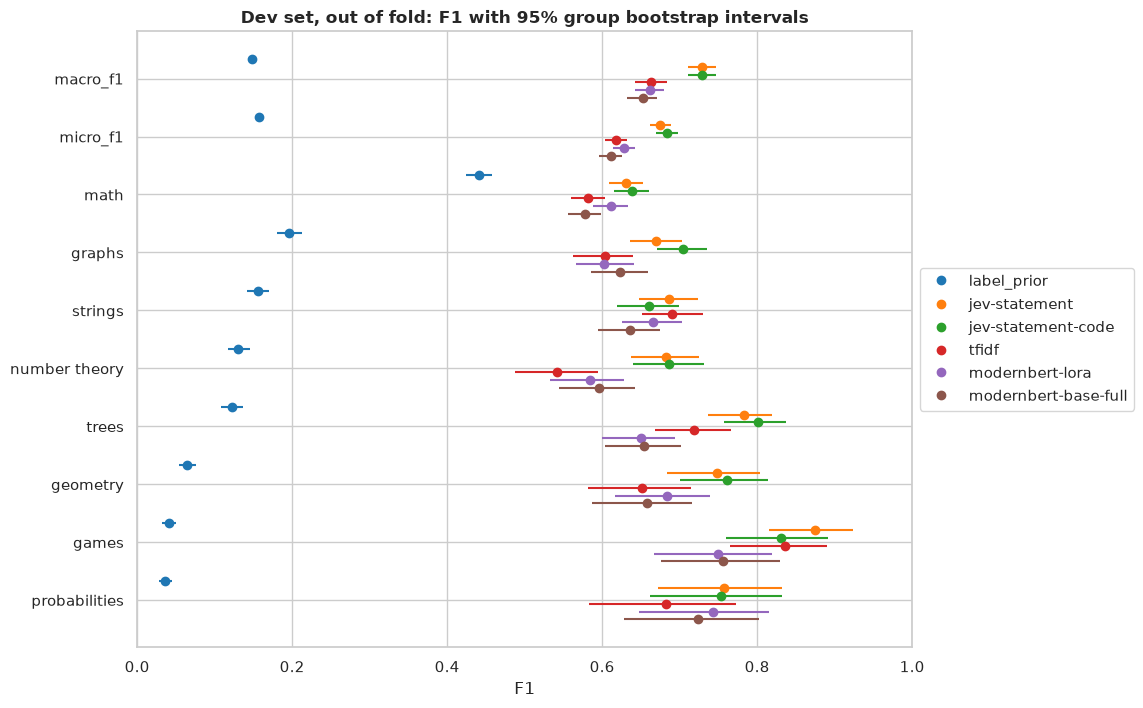

In [11]:
ax = plot_method_f1(dev_scores)
ax.figure.set_size_inches(10, 8)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Dev set, out of fold: F1 with 95% group bootstrap intervals")
plt.show()

**Against TF-IDF and ModernBERT.** The paired differences of each Jev method with TF-IDF and
with each ModernBERT model (Jev minus the other), on every metric, on all five dev folds and on
folds 1-4, which ModernBERT's tuning did not see: an interval that excludes 0 is a difference
that the resampling of near-duplicate groups does not explain.

In [12]:
# ModernBERT's configuration was chosen on dev fold 0 (ADR 0005): folds 1-4 are free of it.
scopes = {"all folds": np.ones(len(dev), dtype=bool), "folds 1-4": (folds != 0).to_numpy()}
against = {}
for baseline in (TFIDF, LORA, BASE_FULL):
    for scope, rows in scopes.items():
        table = method_scores(
            dev_labels[rows],
            {name: predicted[rows] for name, predicted in dev_by_method.items()},
            groups[rows],
            baseline=baseline,
        )
        jev_rows = table.index.get_level_values("method").isin(NAMES)
        against[(baseline, scope)] = table.loc[jev_rows, ["delta", "delta_low", "delta_high"]]
against_references = pd.concat(against, axis="columns", names=["baseline", "folds"])
against_references.round(3)

baseline                             tfidf                                 \
folds                            all folds                      folds 1-4   
                                     delta delta_low delta_high     delta   
method             metric                                                   
jev-statement      macro_f1          0.066     0.052      0.081     0.067   
                   micro_f1          0.058     0.045      0.072     0.056   
                   math              0.048     0.026      0.070     0.044   
                   graphs            0.067     0.036      0.098     0.075   
                   strings          -0.004    -0.038      0.029    -0.006   
                   number theory     0.141     0.093      0.192     0.125   
                   trees             0.064     0.030      0.097     0.074   
                   geometry          0.097     0.044      0.151     0.098   
                   games             0.040    -0.010      0.093     0.031   
                   probabilities     0.076     0.027      0.135     0.092   
jev-statement-code macro_f1          0.066     0.050      0.083     0.067   
                   micro_f1          0.066     0.052      0.080     0.065   
                   math              0.056     0.033      0.079     0.053   
                   graphs            0.101     0.068      0.132     0.110   
                   strings          -0.030    -0.068      0.008    -0.032   
                   number theory     0.146     0.094      0.196     0.127   
                   trees             0.082     0.048      0.116     0.093   
                   geometry          0.109     0.057      0.166     0.102   
                   games            -0.005    -0.072      0.061    -0.018   
                   probabilities     0.072     0.017      0.136     0.099   

baseline                                              modernbert-lora  \
folds                                                       all folds   
                                 delta_low delta_high           delta   
method             metric                                               
jev-statement      macro_f1          0.050      0.083           0.068   
                   micro_f1          0.042      0.071           0.047   
                   math              0.020      0.068           0.019   
                   graphs            0.038      0.111           0.068   
                   strings          -0.043      0.033           0.021   
                   number theory     0.072      0.179           0.098   
                   trees             0.038      0.114           0.133   
                   geometry          0.040      0.157           0.065   
                   games            -0.018      0.084           0.125   
                   probabilities     0.035      0.160           0.015   
jev-statement-code macro_f1          0.050      0.084           0.068   
                   micro_f1          0.050      0.081           0.056   
                   math              0.028      0.078           0.027   
                   graphs            0.073      0.149           0.101   
                   strings          -0.073      0.009          -0.005   
                   number theory     0.071      0.182           0.102   
                   trees             0.055      0.134           0.151   
                   geometry          0.037      0.161           0.078   
                   games            -0.089      0.051           0.080   
                   probabilities     0.040      0.171           0.011   

baseline                                                                   \
folds                                                 folds 1-4             
                                 delta_low delta_high     delta delta_low   
method             metric                                                   
jev-statement      macro_f1          0.053      0.083     0.067     0.050   
             

**Both Jev methods beat every other method on the dev set, out of fold, by about 0.07 of macro F1.** `jev-statement` reaches a macro F1 of 0.729 [0.710, 0.747] and a micro F1 of 0.675 [0.662, 0.689]; `jev-statement-code` reaches 0.729 [0.710, 0.746] and 0.684 [0.670, 0.698]. The label prior, the floor, scores 0.149; TF-IDF 0.663 [0.642, 0.683]; ModernBERT-large with LoRA 0.661 [0.642, 0.680] and ModernBERT-base fully fine-tuned 0.653 [0.632, 0.671].

- Against the floor, `jev-statement-code` gains +0.581 [0.561, 0.598] of macro F1.
- Against the stronger ModernBERT model, ModernBERT-large with LoRA, `jev-statement` gains +0.068 [0.053, 0.083] on all folds and +0.067 [0.050, 0.084] on folds 1-4, and `jev-statement-code` gains +0.068 [0.052, 0.084] and +0.067 [0.051, 0.084]: leaving out fold 0, where ModernBERT's configuration was chosen, changes nothing.
- Against TF-IDF, `jev-statement` gains +0.066 [0.052, 0.081] on all folds and +0.067 [0.050, 0.083] on folds 1-4, and `jev-statement-code` +0.066 [0.050, 0.083] and +0.067 [0.050, 0.084].
- `jev-statement-code`'s best tag is trees (0.801) and its worst is math (0.638).
- Against ModernBERT-large with LoRA on all folds, `jev-statement-code`'s interval excludes 0 on six tags, all in its favour: math +0.027 [0.004, 0.050], graphs +0.101 [0.071, 0.129], number theory +0.102 [0.056, 0.148], trees +0.151 [0.111, 0.193], geometry +0.078 [0.028, 0.129] and games +0.080 [0.020, 0.142]. On strings (-0.005 [-0.037, 0.027]) and probabilities (+0.011 [-0.043, 0.065]) its interval includes 0; on no tag is it worse.

A zero-shot judge that learned nothing from the dev labels but its eight thresholds sits well above the floor, and above both fine-tuned models and the tuned TF-IDF baseline in macro and micro F1.

## 4. The statement against the statement and the solution

The two methods ask the same questions, and `jev-statement-code` also shows Jev the solution.
Their paired difference on the dev set, out of fold, says what the solution adds; whether it
helps is concluded here, on dev, and never on test (ADR 0003).

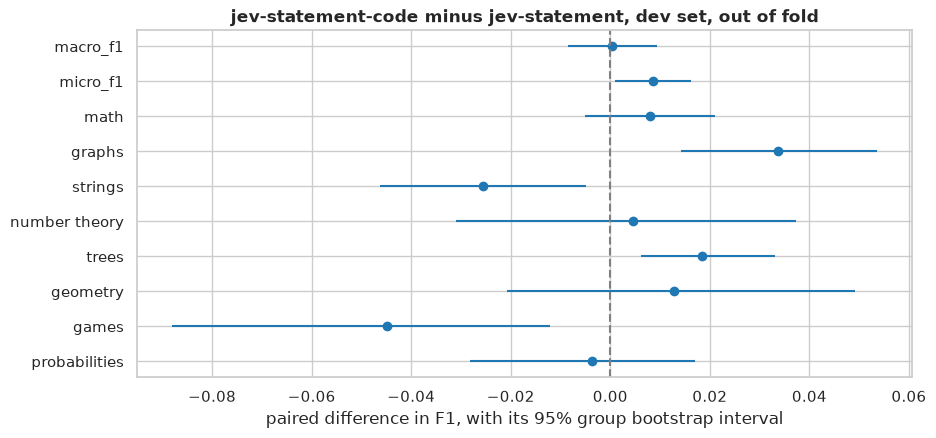

,baseline,candidate,delta,delta_low,delta_high
metric,,,,,
macro_f1,0.729,0.729,0.000,-0.008,0.009
micro_f1,0.675,0.684,0.008,0.001,0.016
math,0.630,0.638,0.008,-0.005,0.021
graphs,0.670,0.704,0.034,0.014,0.054
strings,0.686,0.660,-0.025,-0.046,-0.005
number theory,0.682,0.687,0.005,-0.031,0.037
trees,0.782,0.801,0.018,0.006,0.033
geometry,0.748,0.761,0.013,-0.021,0.049
games,0.875,0.830,-0.045,-0.088,-0.012


In [13]:
solution_effect = compare(
    dev_labels, dev_by_method["jev-statement"], dev_by_method["jev-statement-code"], groups
)
ax = plot_intervals(solution_effect, "delta", "delta_low", "delta_high")
ax.axvline(0, color="grey", linestyle="--")
ax.set(
    title="jev-statement-code minus jev-statement, dev set, out of fold",
    xlabel="paired difference in F1, with its 95% group bootstrap interval",
)
plt.show()
solution_effect.round(3)

**The solution does not raise Jev's macro F1: it trades tags against each other.** `jev-statement-code` minus `jev-statement` is 0.000 [-0.008, 0.009] in macro F1 and +0.008 [0.001, 0.016] in micro F1.

- Its interval excludes 0 on four tags: in favour of the solution on graphs (+0.034 [0.014, 0.054]) and trees (+0.018 [0.006, 0.033]), against it on strings (-0.025 [-0.046, -0.005]) and games (-0.045 [-0.088, -0.012]). With eight comparisons one tag can differ by chance, but four do, in both directions.
- The solution raises the input of a dev problem from 2,770 tokens to 3,198.

On dev, the solution is not worth its tokens for the primary metric: it buys a small micro F1 gain and moves F1 from strings and games to graphs and trees, for about 15% more input.

## 5. Calibration

A probability is calibrated when, among the problems given about 0.7 for a tag, about 70% have
the tag. The reliability table cuts [0, 1] into 10 bins of equal width (`CALIBRATION_BINS`) and
compares, per tag and bin, the mean probability with the share of problems that have the tag;
the expected calibration error is their mean gap, weighted by the bins' problems. Each method's
table follows its plot: one row per tag, and per bin the mean probability, the share of problems
with the tag and their count (NaN for a bin without a problem). A failed answer scores 0 on
every tag, so it falls in the first bin. Then the final thresholds of each method, chosen on
every dev problem, and a fixed threshold of 0.5 against the cross-fitted thresholds, paired. A
threshold of 0.5 maximises the accuracy of a calibrated probability, not its F1: the F1-optimal
threshold of a calibrated score is half the F1 it reaches, so thresholds below 0.5 are expected
even from calibrated probabilities, and only the reliability curves speak to calibration.
Neither chooses anything: the methods were frozen with their cross-fitted thresholds.

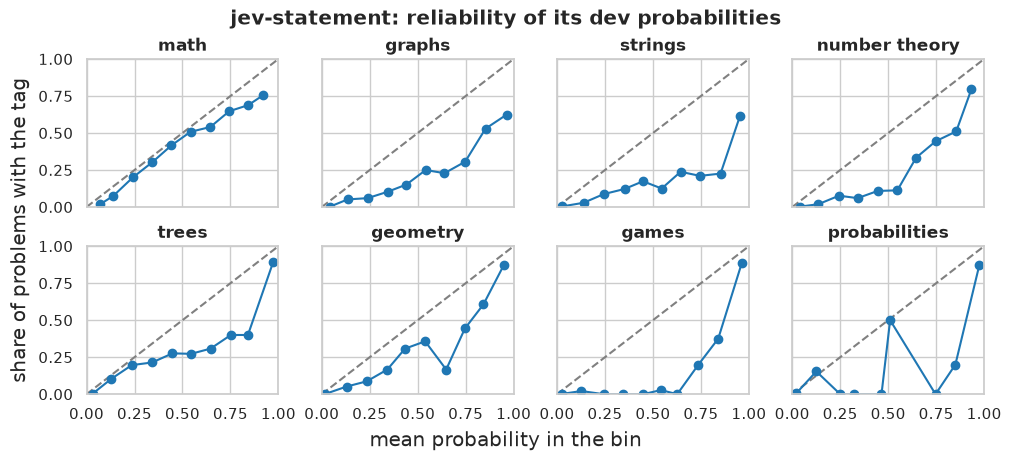

mean_probability                                            \
bin                          0      1      2      3      4      5      6   
tag                                                                        
math                     0.070  0.140  0.241  0.343  0.443  0.542  0.645   
graphs                   0.042  0.135  0.239  0.343  0.441  0.542  0.639   
strings                  0.024  0.138  0.243  0.352  0.448  0.546  0.644   
number theory            0.041  0.135  0.244  0.340  0.445  0.548  0.645   
trees                    0.032  0.129  0.236  0.342  0.448  0.545  0.646   
geometry                 0.019  0.130  0.235  0.342  0.434  0.539  0.648   
games                    0.025  0.127  0.243  0.342  0.448  0.542  0.626   
probabilities            0.020  0.125  0.250  0.320  0.465  0.510    NaN   

                                   positive_rate                              \
bin                7      8      9             0      1      2      3      4   
tag                                                                            
math           0.744  0.843  0.920         0.018  0.076  0.200  0.303  0.417   
graphs         0.747  0.853  0.963         0.003  0.051  0.060  0.103  0.152   
strings        0.745  0.852  0.953         0.004  0.029  0.087  0.122  0.174   
number theory  0.748  0.854  0.933         0.003  0.019  0.077  0.060  0.109   
trees          0.752  0.841  0.973         0.004  0.104  0.196  0.214  0.276   
geometry       0.746  0.842  0.948         0.002  0.052  0.087  0.167  0.308   
games          0.737  0.840  0.963         0.002  0.021  0.000  0.000  0.000   
probabilities  0.747  0.850  0.975         0.005  0.154  0.000  0.000  0.000   

                                                 problems                 \
bin                5      6      7      8      9        0       1      2   
tag                                                                        
math           0.508  0.540  0.647  0.688  0.756    502.0  1065.0  646.0   
graphs         0.250  0.229  0.306  0.529  0.624   2391.0   506.0  200.0   
strings        0.125  0.238  0.211  0.226  0.614   3045.0   140.0   69.0   
number theory  0.113  0.333  0.444  0.511  0.795   2771.0   371.0  196.0   
trees          0.273  0.308  0.400  0.400  0.893   3403.0   222.0   56.0   
geometry       0.357  0.167  0.444  0.606  0.871   3620.0   135.0   46.0   
games          0.028  0.000  0.200  0.375  0.886   3737.0    47.0   17.0   
probabilities  0.500    NaN  0.000  0.200  0.875   3903.0    13.0    2.0   

                                                                
bin                3      4      5      6      7      8      9  
tag                                                             
math           386.0  300.0  246.0  235.0  258.0  260.0   90.0  
graphs          97.0   79.0   72.0   70.0   49.0   85.0  439.0  
strings         41.0   46.0   40.0   42.0   57.0   93.0  415.0  
number theory  100.0   92.0   71.0   63.0   81.0   92.0  151.0  
trees           28.0   29.0   11.0   13.0   10.0   10.0  206.0  
geometry        12.0   13.0   14.0   12.0   18.0   33.0   85.0  
games           16.0   30.0   36.0    8.0   10.0    8.0   79.0  
probabilities    2.0    2.0    2.0    NaN    3.0    5.0   56.0

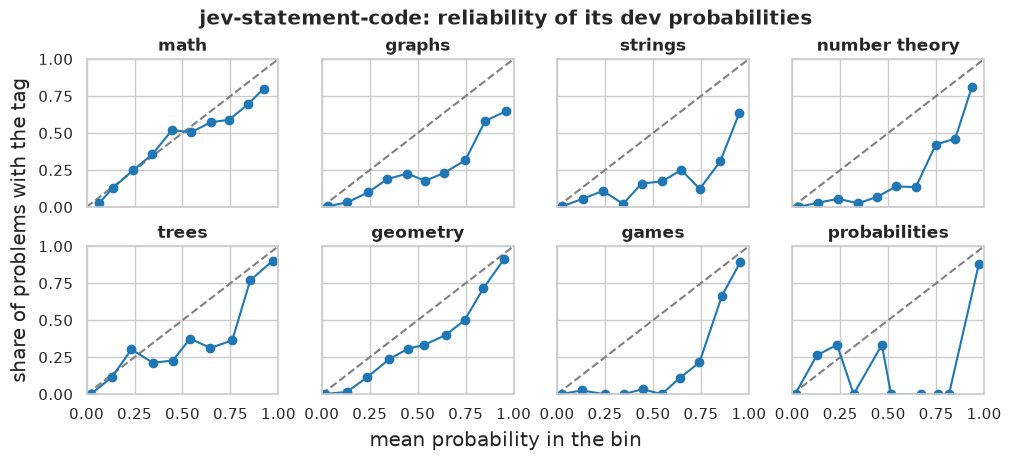

mean_probability                                            \
bin                          0      1      2      3      4      5      6   
tag                                                                        
math                     0.067  0.137  0.242  0.342  0.446  0.545  0.646   
graphs                   0.035  0.134  0.243  0.342  0.446  0.538  0.638   
strings                  0.024  0.137  0.239  0.344  0.440  0.548  0.648   
number theory            0.035  0.137  0.239  0.344  0.442  0.542  0.644   
trees                    0.026  0.133  0.234  0.346  0.449  0.540  0.646   
geometry                 0.017  0.131  0.237  0.353  0.450  0.534  0.647   
games                    0.024  0.129  0.252  0.348  0.446  0.545  0.641   
probabilities            0.017  0.128  0.233  0.320  0.467  0.515  0.670   

                                   positive_rate                              \
bin                7      8      9             0      1      2      3      4   
tag                                                                            
math           0.743  0.841  0.924         0.029  0.128  0.247  0.356  0.520   
graphs         0.748  0.852  0.960         0.006  0.032  0.100  0.189  0.226   
strings        0.744  0.850  0.951         0.004  0.057  0.109  0.021  0.158   
number theory  0.748  0.849  0.937         0.001  0.030  0.055  0.025  0.069   
trees          0.759  0.853  0.970         0.004  0.116  0.302  0.212  0.227   
geometry       0.744  0.842  0.952         0.002  0.015  0.114  0.238  0.308   
games          0.742  0.860  0.955         0.002  0.025  0.000  0.000  0.034   
probabilities  0.760  0.817  0.972         0.004  0.263  0.333  0.000  0.333   

                                                 problems                  \
bin                5      6      7      8      9        0     1    2    3   
tag                                                                         
math           0.504  0.572  0.590  0.694  0.800      892  1077  474  323   
graphs         0.176  0.231  0.316  0.583  0.646     2830   284  110   53   
strings        0.174  0.250  0.123  0.308  0.638     3062   141   55   47   
number theory  0.139  0.134  0.422  0.462  0.814     2799   299  163  119   
trees          0.375  0.312  0.364  0.769  0.901     3510   121   43   33   
geometry       0.333  0.400  0.500  0.714  0.917     3634   130   35   21   
games          0.000  0.111  0.214  0.667  0.893     3750    40   16   22   
probabilities  0.000  0.000  0.000  0.000  0.877     3897    19    3    2   

                                             
bin              4    5    6    7    8    9  
tag                                          
math           202  226  208  239  242  105  
graphs          53   34   39   38   72  475  
strings         38   46   44   57  117  381  
number theory  102   79   67   64  119  177  
trees           22   16   16   11   13  203  
geometry        13    9   15   24   35   72  
games           29   27    9   14    6   75  
probabilities    3    2    1    1    3   57

failed dev answers, scored 0 on every tag: {'jev-statement': 0, 'jev-statement-code': 0}


,jev-statement,jev-statement-code
tag,,
math,0.065,0.044
graphs,0.117,0.090
strings,0.093,0.090
number theory,0.092,0.097
trees,0.036,0.030
geometry,0.027,0.025
games,0.039,0.036
probabilities,0.018,0.016


In [14]:
dev_probabilities = {name: jev_scores[name].loc["dev"] for name in NAMES}
for name, probabilities in dev_probabilities.items():
    assert probabilities.index.equals(dev.index), name
    reliability = reliability_table(probabilities, dev_labels)
    figure = plot_reliability_table(reliability)
    figure.suptitle(f"{name}: reliability of its dev probabilities", fontweight="bold")
    plt.show()
    display(reliability.unstack("bin").round(3))
failed_dev = {name: int(usage.at[(name, "dev"), "failed"]) for name in NAMES}
print(f"failed dev answers, scored 0 on every tag: {failed_dev}")
calibration_error = pd.DataFrame(
    {name: expected_calibration_error(dev_probabilities[name], dev_labels) for name in NAMES}
)
calibration_error.round(3)

In [15]:
final_thresholds = pd.DataFrame(
    {name: load_method(model_dir(name)).thresholds.thresholds_ for name in NAMES}, index=TAGS
)
display(final_thresholds.round(3))
half = pd.Series(0.5, index=TAGS)
fixed_half = pd.concat(
    {
        name: compare(
            dev_labels,
            dev_by_method[name],
            apply_thresholds(dev_probabilities[name], half),
            groups,
        )
        for name in NAMES
    },
    names=["method"],
)
fixed_half.round(3)

,jev-statement,jev-statement-code
math,0.335,0.335
graphs,0.725,0.745
strings,0.885,0.895
number theory,0.735,0.695
trees,0.830,0.645
geometry,0.775,0.615
games,0.925,0.820
probabilities,0.880,0.870


baseline  candidate  delta  delta_low  \
method             metric                                                 
jev-statement      macro_f1          0.729      0.676 -0.053     -0.065   
                   micro_f1          0.675      0.641 -0.034     -0.044   
                   math              0.630      0.601 -0.029     -0.046   
                   graphs            0.670      0.641 -0.029     -0.049   
                   strings           0.686      0.616 -0.070     -0.098   
                   number theory     0.682      0.630 -0.052     -0.082   
                   trees             0.782      0.779 -0.004     -0.025   
                   geometry          0.748      0.739 -0.009     -0.048   
                   games             0.875      0.676 -0.199     -0.271   
                   probabilities     0.758      0.729 -0.029     -0.064   
jev-statement-code macro_f1          0.729      0.690 -0.039     -0.053   
                   micro_f1          0.684      0.648 -0.036     -0.046   
                   math              0.638      0.583 -0.055     -0.073   
                   graphs            0.704      0.689 -0.015     -0.033   
                   strings           0.660      0.621 -0.039     -0.071   
                   number theory     0.687      0.628 -0.059     -0.097   
                   trees             0.801      0.800 -0.001     -0.024   
                   geometry          0.761      0.778  0.017     -0.008   
                   games             0.830      0.698 -0.133     -0.208   
                   probabilities     0.754      0.725 -0.029     -0.065   

                                  delta_high  
method             metric                     
jev-statement      macro_f1           -0.040  
                   micro_f1           -0.024  
                   math               -0.012  
                   graphs             -0.010  
                   strings            -0.042  
                   number theory      -0.023  
                   trees               0.019  
                   geometry            0.029  
                   games              -0.131  
                   probabilities       0.004  
jev-statement-code macro_f1           -0.025  
                   micro_f1           -0.026  
                   math               -0.038  
                   graphs              0.002  
                   strings            -0.007  
                   number theory      -0.019  
                   trees               0.024  
                   geometry            0.045  
                   games              -0.061  
                   probabilities       0.004

**Jev's probabilities are too high above the lowest bins on most tags, so its F1-optimal thresholds sit well above 0.5.** No dev answer failed, for either method, so no score is a zero from a refused request.

- The expected calibration error of `jev-statement` goes from 0.018 (probabilities) to 0.117 (graphs), and that of `jev-statement-code` from 0.016 (probabilities) to 0.097 (number theory). The small errors of the rare tags come from their first bin, which holds nearly every problem.
- The reliability tables show, bin by bin, a share of problems with the tag far below the mean probability in the middle bins: for `jev-statement-code`, graphs in bin 5 (mean probability 0.538, share 0.176), number theory in bin 6 (0.644 against 0.134) and strings in bin 7 (0.744 against 0.123); games and probabilities behave the same, on few problems per bin. Math is the exception, close to the diagonal (bin 4: 0.446 against 0.520, slightly too low), and geometry is the closest of the others.
- `jev-statement-code`'s final thresholds go from 0.335 (math) to 0.895 (strings), every one above 0.5 but math's. For a calibrated score, the F1-optimal threshold is half its F1, so a threshold below 0.5 would say nothing against calibration; these thresholds are well above half each tag's F1, which agrees with the tables: the probabilities are too high. Math's 0.335 is about half its F1 of 0.638, as its near-calibrated curve predicts.
- A fixed 0.5 threshold in place of the cross-fitted ones costs `jev-statement` -0.053 [-0.065, -0.040] of macro F1 and `jev-statement-code` -0.039 [-0.053, -0.025]; games loses the most (-0.199 [-0.271, -0.131] and -0.133 [-0.208, -0.061]).

The probabilities rank problems well, but they are not calibrated: the cross-fitted thresholds, learned out of fold on dev labels, are what turns them into tags.

## 6. Slices: release era and self-identifying solutions

**Release era.** Statements switched from flattened Unicode math to `$$$` LaTeX in 2018, and
the share of `math` rose after 2019, so a method may score differently on the two eras for
reasons other than the content. **Self-identifying solutions.** In 50 dev problems, the solution
names its own Codeforces problem (a URL, a round or problem id, a quote of the statement, a
class named after the task): a model that memorised Codeforces could read the tags off it, and
`jev-statement-code` sees the solution. Every method's macro F1 is reported with and without
these problems; on so few problems, only the micro F1 means something.

In [16]:
by_era = {
    name: evaluate(dev_labels, predicted, release_years=years, groups=groups)
    for name, predicted in dev_by_method.items()
}
era_columns = ["problems", "macro_f1", "macro_f1_low", "macro_f1_high"]
display(
    pd.concat(
        {name: result.summary[era_columns] for name, result in by_era.items()}, names=["method"]
    ).round(3)
)
code_by_era = by_era["jev-statement-code"]
code_by_era.per_tag["f1"].unstack("slice").loc[TAGS, code_by_era.summary.index].round(3)

problems  macro_f1  macro_f1_low  \
method               slice                                            
label_prior          all problems      3988     0.149         0.144   
                     focus-tagged      2143     0.250         0.246   
                     up to 2017        1626     0.128         0.121   
                     from 2018         2362     0.161         0.155   
jev-statement        all problems      3988     0.729         0.710   
                     focus-tagged      2143     0.788         0.770   
                     up to 2017        1626     0.735         0.709   
                     from 2018         2362     0.718         0.690   
jev-statement-code   all problems      3988     0.729         0.710   
                     focus-tagged      2143     0.786         0.768   
                     up to 2017        1626     0.743         0.717   
                     from 2018         2362     0.713         0.686   
tfidf                all problems      3988     0.663         0.642   
                     focus-tagged      2143     0.729         0.709   
                     up to 2017        1626     0.662         0.628   
                     from 2018         2362     0.653         0.623   
modernbert-lora      all problems      3988     0.661         0.642   
                     focus-tagged      2143     0.733         0.714   
                     up to 2017        1626     0.664         0.633   
                     from 2018         2362     0.653         0.623   
modernbert-base-full all problems      3988     0.653         0.632   
                     focus-tagged      2143     0.724         0.703   
                     up to 2017        1626     0.654         0.621   
                     from 2018         2362     0.644         0.613   

                                   macro_f1_high  
method               slice                        
label_prior          all problems          0.153  
                     focus-tagged          0.255  
                     up to 2017            0.135  
                     from 2018             0.167  
jev-statement        all problems          0.747  
                     focus-tagged          0.805  
                     up to 2017            0.759  
                     from 2018             0.742  
jev-statement-code   all problems          0.746  
                     focus-tagged          0.803  
                     up to 2017            0.766  
                     from 2018             0.737  
tfidf                all problems          0.683  
                     focus-tagged          0.749  
                     up to 2017            0.692  
                     from 2018             0.679  
modernbert-lora      all problems          0.680  
                     focus-tagged          0.751  
                     up to 2017            0.691  
                     from 2018             0.678  
modernbert-base-full all problems          0.671  
                     focus-tagged          0.743  
                     up to 2017            0.683  
                     from 2018             0.668

slice,all problems,focus-tagged,up to 2017,from 2018
tag,,,,
math,0.638,0.734,0.555,0.676
graphs,0.704,0.752,0.733,0.683
strings,0.660,0.791,0.646,0.670
number theory,0.687,0.711,0.678,0.691
trees,0.801,0.827,0.787,0.809
geometry,0.761,0.843,0.776,0.739
games,0.830,0.857,0.868,0.811
probabilities,0.754,0.778,0.900,0.629


In [17]:
in_slice = dev.index.isin(load_slice().index)
print(
    f"self-identifying solutions: {in_slice.sum()} dev problems in "
    f"{groups[in_slice].nunique()} near-duplicate groups; positives per tag: "
    f"{dev_labels[in_slice].sum().to_dict()}"
)
without = method_scores(
    dev_labels[~in_slice],
    {name: predicted[~in_slice] for name, predicted in dev_by_method.items()},
    groups[~in_slice],
)
slices_macro = pd.DataFrame(
    {
        "all dev problems": dev_scores.xs("macro_f1", level="metric")["f1"],
        "without the self-identifying": without.xs("macro_f1", level="metric")["f1"],
    }
)
slices_macro["change"] = slices_macro.iloc[:, 1] - slices_macro.iloc[:, 0]
slices_macro["micro F1 on the slice"] = pd.Series(
    {
        name: evaluate(dev_labels[in_slice], predicted[in_slice]).micro_f1
        for name, predicted in dev_by_method.items()
    }
)
display(slices_macro.round(3))
solution_on_slice = compare(
    dev_labels[in_slice],
    dev_by_method["jev-statement"][in_slice],
    dev_by_method["jev-statement-code"][in_slice],
    groups[in_slice],
)
solution_on_slice.loc[["macro_f1", "micro_f1"]].round(3)

self-identifying solutions: 50 dev problems in 49 near-duplicate groups; positives per tag: {'math': 9, 'graphs': 12, 'strings': 4, 'number theory': 1, 'trees': 7, 'geometry': 1, 'games': 2, 'probabilities': 0}


,all dev problems,without the self-identifying,change,micro F1 on the slice
method,,,,
label_prior,0.149,0.148,-0.000,0.165
jev-statement,0.729,0.730,0.001,0.619
jev-statement-code,0.729,0.730,0.001,0.635
tfidf,0.663,0.663,0.000,0.550
modernbert-lora,0.661,0.662,0.001,0.541
modernbert-base-full,0.653,0.654,0.001,0.468


,baseline,candidate,delta,delta_low,delta_high
metric,,,,,
macro_f1,0.540,0.542,0.002,-0.051,0.066
micro_f1,0.619,0.635,0.016,-0.058,0.085


**Jev's score holds across release eras and owes nothing to self-identifying solutions.**

- Up to 2017 (1,626 dev problems), `jev-statement-code` reaches a macro F1 of 0.743 [0.717, 0.766]; from 2018 (2,362 problems), 0.713 [0.686, 0.737]. The two intervals overlap.
- `jev-statement` reaches 0.735 up to 2017 and 0.718 from 2018; ModernBERT-large with LoRA 0.664 and 0.653.
- The self-identifying slice holds 50 dev problems. On it, `jev-statement` reaches a micro F1 of 0.619 and `jev-statement-code` 0.635, a paired difference of +0.016 [-0.058, 0.085], against +0.008 [0.001, 0.016] on every dev problem (section 4): the solution that names its problem gives no measurable gain.
- Leaving the slice out changes a method's macro F1 by at most 0.001.

No release-era confound and no contamination through the solution shows in these numbers.

## 7. Agreement and errors

On the dev set, out of fold. First, on each tag, the problems that `jev-statement-code` (a) and
a ModernBERT model (b) both get right, those only one of them gets right, and those both get
wrong (a true negative counts as right). Problems that only one method gets right are room for a
method that combines them. Then the errors of `jev-statement-code`: its false positives and
false negatives per tag, how many of the false positives fall on problems with no focus tag,
and the first misread problems of its weakest tag and of `games`, whose definition excludes
an Alice and a Bob who play no game.

In [18]:
agreements = pd.concat(
    {
        baseline: agreement(
            dev_labels, dev_by_method["jev-statement-code"], dev_by_method[baseline]
        )
        for baseline in (LORA, BASE_FULL)
    },
    axis="columns",
    names=["b"],
)
agreements.loc["all tags"] = agreements.sum()
agreements

b             modernbert-lora                                       \
                   both_right only_a_right only_b_right both_wrong   
tag                                                                  
math                     2564          508          437        479   
graphs                   3568          127           69        224   
strings                  3654           85           79        170   
number theory            3673          138           62        115   
trees                    3794           98           17         79   
geometry                 3880           42           18         48   
games                    3938           23            8         19   
probabilities            3947            9            5         27   
all tags                29018         1030          695       1161   

b             modernbert-base-full                                       
                        both_right only_a_right only_b_right both_wrong  
tag                                                                      
math                          2385          687          415        501  
graphs                        3551          144          122        171  
strings                       3612          127          102        147  
number theory                 3702          109           72        105  
trees                         3812           80            9         87  
geometry                      3866           56           22         44  
games                         3945           16            5         22  
probabilities                 3941           15            8         24  
all tags                     28814         1234          755       1101

In [19]:
predicted = dev_by_method["jev-statement-code"]
false_positives = (predicted == 1) & (dev_labels == 0)
no_focus = dev_labels.sum(axis="columns") == 0
code_per_tag = code_by_era.per_tag.loc[ALL_PROBLEMS]
errors = pd.DataFrame(
    {
        "false_positives": false_positives.sum(),
        "on_no_focus_problems": false_positives[no_focus].sum(),
        "false_negatives": ((predicted == 0) & (dev_labels == 1)).sum(),
        "precision": code_per_tag["precision"],
        "recall": code_per_tag["recall"],
    }
)
nothing_predicted = code_by_era.summary.at[ALL_PROBLEMS, "no_focus_nothing_predicted"]
print(f"share of the no-focus dev problems given no tag: {nothing_predicted:.3f}")
errors.round(3)

share of the no-focus dev problems given no tag: 0.714


,false_positives,on_no_focus_problems,false_negatives,precision,recall
math,597,329,319,0.575,0.717
graphs,207,63,86,0.627,0.802
strings,154,121,95,0.611,0.718
number theory,93,19,84,0.676,0.698
trees,28,15,68,0.873,0.739
geometry,38,27,28,0.734,0.789
games,9,5,18,0.880,0.786
probabilities,7,4,25,0.875,0.662


In [20]:
weakest = dev_f1.loc[TAGS, "jev-statement-code"].idxmin()
cases = [(weakest, "false positive"), (weakest, "false negative"), ("games", "false positive")]
for tag, kind in dict.fromkeys(cases):
    print(f"{kind}s of jev-statement-code on {tag}, the first 3 dev problems:")
    display(misclassified(dev, dev_labels, predicted, tag, kind, limit=3))

false positives of jev-statement-code on math, the first 3 dev problems:


,tags,statement
sample_id,,
16,[greedy],"Recently, Duff has been practicing weight lifting. As a hard practice, Malek gave her a task. He gave her ..."
28,"[constructive algorithms, geometry]","As some of you know, cubism is a trend in art, where the problem of constructing volumetrical shape on a..."
38,"[dp, combinatorics, brute force]","The Travelling Salesman spends a lot of time travelling so he tends to get bored. To pass time, he likes t..."


false negatives of jev-statement-code on math, the first 3 dev problems:


,tags,statement
sample_id,,
0,"[greedy, constructive algorithms, math, implementation, data structures]","Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one ..."
2,"[dp, greedy, math]",You are playing a game where your character should overcome different obstacles. The current problem is to...
4,"[binary search, divide and conquer, brute force, math]","Thanos wants to destroy the avengers base, but he needs to destroy the avengers along with their base. Let..."


false positives of jev-statement-code on games, the first 3 dev problems:


,tags,statement
sample_id,,
271,"[data structures, implementation, math]","Two people are playing a game with a string $$$s$$$, consisting of lowercase latin letters. On a player's ..."
629,"[sortings, greedy]",Two players A and B have a list of $$$n$$$ integers each. They both want to maximize the subtraction betwe...
2117,[sortings],"Two players play a game. Initially there are $$$n$$$ integers $$$a_1, a_2, \ldots, a_n$$$ written on the b..."


**Jev and ModernBERT err on different problem-tag pairs, and Jev's errors are mostly false positives on math.**

- Against ModernBERT-large with LoRA, the stronger ModernBERT model, over the eight tags: 1,030 problem-tag pairs only `jev-statement-code` gets right, 695 only ModernBERT gets right, and 1,161 both get wrong.
- Math has the most false positives: 597, 329 of them on problems with no focus tag, for a precision of 0.575 and a recall of 0.717.
- Over all tags, 583 of the 1,133 false positives fall on problems with no focus tag, and 0.714 of the no-focus dev problems get no tag.
- The misread problems share a story that suggests a tag their intended solution does not need. Problems 16 (greedy), 28 (constructive algorithms, geometry) and 38 (dp, combinatorics, brute force) read as math; problems 0, 2 and 4 carry math only beside greedy, dp or binary search, and are missed. On games, problems 271, 629 and 2117 tell of two players, but Codeforces tags them by their technique (data structures, sortings, greedy), and Jev answers yes.

The two models' errors overlap only in part, which leaves room for a composite method; Jev's main weakness is the math tag, which Codeforces gives by technique, not by the arithmetic of the statement.

## 8. The test set, reported once

Each method's frozen test predictions, scored once, side by side. Nothing is chosen from them:
the methods and their thresholds were fixed on dev (ADR 0001, ADR 0003), and the CLI's method is
chosen on dev alone (ADR 0004). The Jev methods and TF-IDF apply the thresholds chosen on every
dev problem to their test scores. ModernBERT's test predictions come from the bag of its five
fold models, while its dev predictions came from each fold model alone.

In [21]:
test_results = {
    name: evaluate(test_labels, predicted, release_years=release_years(test), groups=test["group"])
    for name, predicted in test_by_method.items()
}
test_f1 = pd.DataFrame({name: result.overall_f1() for name, result in test_results.items()})
display(test_f1.round(3))
test_summary = pd.DataFrame(
    {name: result.summary.loc[ALL_PROBLEMS] for name, result in test_results.items()}
).T
interval_columns = ["macro_f1", "macro_f1_low", "macro_f1_high"]
test_summary[[*interval_columns, "micro_f1", "micro_f1_low", "micro_f1_high"]].round(3)

,label_prior,jev-statement,jev-statement-code,tfidf,modernbert-lora,modernbert-base-full
metric,,,,,,
macro_f1,0.149,0.737,0.751,0.689,0.695,0.704
micro_f1,0.158,0.683,0.694,0.633,0.649,0.663
math,0.441,0.656,0.659,0.619,0.641,0.653
graphs,0.196,0.672,0.713,0.557,0.586,0.618
strings,0.158,0.654,0.663,0.660,0.654,0.657
number theory,0.135,0.684,0.659,0.518,0.611,0.607
trees,0.119,0.769,0.767,0.772,0.727,0.768
geometry,0.064,0.690,0.781,0.706,0.645,0.676
games,0.041,0.927,0.927,0.878,0.878,0.811


,macro_f1,macro_f1_low,macro_f1_high,micro_f1,micro_f1_low,micro_f1_high
label_prior,0.149,0.139,0.158,0.158,0.148,0.168
jev-statement,0.737,0.703,0.765,0.683,0.656,0.708
jev-statement-code,0.751,0.720,0.777,0.694,0.668,0.719
tfidf,0.689,0.649,0.721,0.633,0.604,0.661
modernbert-lora,0.695,0.658,0.727,0.649,0.621,0.677
modernbert-base-full,0.704,0.666,0.737,0.663,0.636,0.690


**On the test set, reported once and never used to choose, both Jev methods stay ahead.** `jev-statement` reaches a macro F1 of 0.737 [0.703, 0.765] and `jev-statement-code` 0.751 [0.720, 0.777]. The label prior scores 0.149, ModernBERT-large with LoRA (its bag) 0.695, ModernBERT-base fully fine-tuned (its bag) 0.704, and TF-IDF 0.689. Each Jev method's dev out-of-fold macro F1, 0.729, lies inside its test interval.

## 9. Latency

`tracking latency` loaded each Jev method's frozen folder and timed one prediction per problem
on 50 dev problems (`LATENCY_PROBLEMS`, drawn with `LATENCY_SEED`): each a live request to Jev,
from opening the client to the 0/1 tags, against the 10-second budget of a single prediction
(`LATENCY_BUDGET_S`). The label prior and the two ModernBERT methods (each the bag of its five
fold models) were timed the same way, on their own problems' predictions.

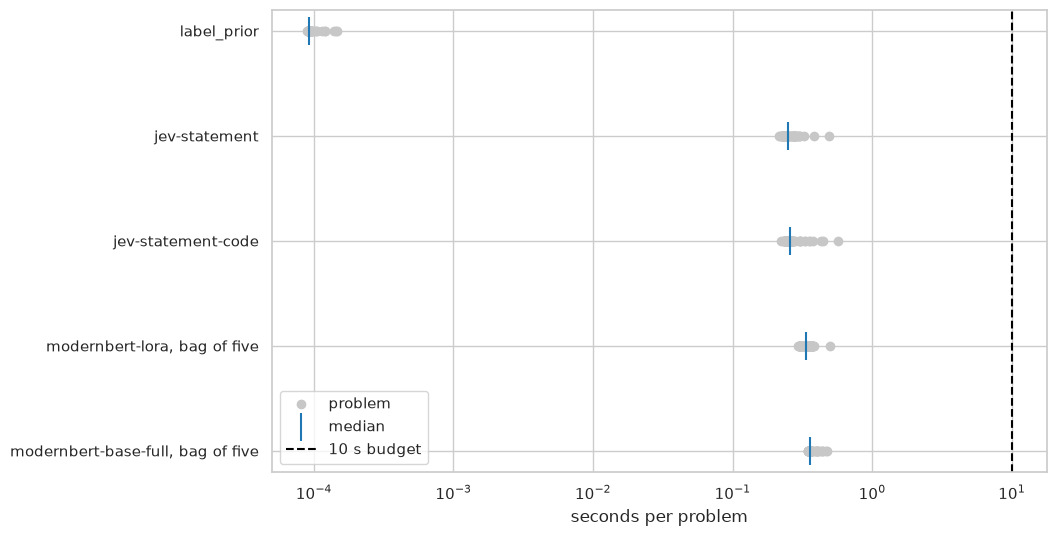

,median_s,p95_s,max_s,under_budget
label_prior,0.000,0.000,0.000,True
jev-statement,0.249,0.315,0.490,True
jev-statement-code,0.260,0.405,0.570,True
"modernbert-lora, bag of five",0.335,0.377,0.498,True
"modernbert-base-full, bag of five",0.360,0.443,0.474,True


,input_tokens,output_tokens,cost_usd,retries,bulk_s
jev-statement,138080,6800,0.0058,0,0.7344
jev-statement-code,158595,6800,0.0067,0,0.7415


In [22]:
timed = {name: load_latency(method_dir(name)) for name in [PRIOR, *NAMES]}
latencies = {name: timing.seconds for name, timing in timed.items()} | modernbert_latency
ax = plot_latency(latencies)
ax.figure.set_size_inches(10, 6)
plt.show()
latency_table = pd.DataFrame(
    {name: latency_summary(seconds) for name, seconds in latencies.items()}
).T
latency_table["under_budget"] = latency_table["max_s"] < LATENCY_BUDGET_S
display(latency_table.round(3))
counts = {"input_tokens": "int64", "output_tokens": "int64", "retries": "int64"}
timed_calls = pd.DataFrame({name: timed[name].calls.sum() for name in NAMES}).T.astype(counts)
timed_calls["bulk_s"] = [timed[name].bulk_s for name in NAMES]
timed_calls.round(4)

**One live prediction takes a quarter of a second, far under the 10-second budget.**

- `jev-statement`: median 0.249 s, maximum 0.490 s; `jev-statement-code`: median 0.260 s, maximum 0.570 s.
- At the pace of the answers files, the 50 timed problems take 0.7344 s and 0.7415 s in bulk.
- The timed requests cost $0.0058 and $0.0067.
- The retries are 0 by construction: the TypeSafe SDK does not report its retries, so a slow maximum may include its backoff.

## 10. Takeaways and next steps

**Results**
- **Section 3, dev out of fold.** `jev-statement` 0.729 [0.710, 0.747] and `jev-statement-code` 0.729 [0.710, 0.746] in macro F1, against 0.663 for TF-IDF, 0.661 and 0.653 for the two ModernBERT models and 0.149 for the floor: +0.068 [0.052, 0.084] over ModernBERT-large with LoRA for `jev-statement-code`.
- **Section 4, the solution.** 0.000 [-0.008, 0.009] in macro F1: it helps graphs and trees and hurts strings and games, for 3,198 input tokens per problem instead of 2,770.
- **Section 5, calibration.** The probabilities are too high above the lowest bins (graphs in bin 5: 0.538 against 0.176) except on math; the cross-fitted thresholds go from 0.335 to 0.895, and a fixed 0.5 threshold costs -0.039 [-0.053, -0.025] for `jev-statement-code`.
- **Section 6, slices.** 0.743 up to 2017 and 0.713 from 2018 for `jev-statement-code`; without the 50 self-identifying problems, a macro F1 changes by at most 0.001.
- **Section 7, errors.** 1,030 pairs only `jev-statement-code` gets right against 695 for ModernBERT-large with LoRA; math has 597 false positives, for a precision of 0.575.
- **Section 8, test, reported once.** 0.737 [0.703, 0.765] and 0.751 [0.720, 0.777], against 0.704 for the best ModernBERT bag and 0.689 for TF-IDF.
- **Section 9, latency.** Medians of 0.249 s and 0.260 s, maxima of 0.490 s and 0.570 s, under the 10-second budget.

A zero-shot System One model, asked one defined question per tag and thresholded out of fold, beats both fine-tuned transformers and the tuned TF-IDF baseline on the dev set by about 0.07 of macro F1, at a quarter of a second and well under a cent per problem; the solution adds tokens, not macro F1, so `jev-statement` is the cheaper of the two equals.

**Next steps**
- **Stack Jev with another method.** A composite method (`depends_on`) that reads Jev's eight
  probabilities beside the scores of TF-IDF or a fine-tuned model, fitted out of fold with
  `cross_predict`, could gain on the problems that only one of them gets right (section 7 counts
  them against ModernBERT).
- **The other 29 tags.** One question per tag, each with a definition written before any
  request, would make Jev a tagger of every tag: a new method under a new name, asked on dev
  first (ADR 0003).
- **Sharper definitions.** The misread dev problems (section 7) may suggest better
  definitions; a changed word is a new method under a new name, and its dev part is asked
  first.
- **The CLI's method** is chosen on dev out-of-fold macro F1 alone, among the eligible frozen
  methods (ADR 0004). A Jev method needs the TypeSafe SDK, a key and the network to predict.